# Rail Detection Deep Learning Project

In [ ]:
# importing packages
import csv
import pandas as pd 
import os 
import shutil
import tensorflow as tf 
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

## Reading the dataset 
Using pandas and shutil to move all the images in the dataset to the correct folder either "defective" or "non_defective" by first reading the csv file which came with the dataset and then finding those images and moving them.

In [18]:
df = pd.read_csv('train _combined.csv')
df.head()

# Sökvägen till varje directory
raw_directory = 'raw_data'
defective_directory = 'data/defective'
non_defective_directory = 'data/non_defective'

# Går igenom csv filen rad för rad 
for index, row in df.iterrows(): 
    file_name = row['images']
    label = row['labels']
    
    # Var bilderna ligger
    source = os.path.join(raw_directory, file_name)
    
    if label == 'Defective':
        destination = os.path.join(defective_directory, file_name)
    else: 
        destination = os.path.join(non_defective_directory, file_name)
    
    # Kolla om bilden redan finns i destination mappen 
    if not os.path.exists(destination):    
        # kopiera bilden till den rätta mappen 
        shutil.copy(source, destination)
    else: 
        # Om den redan finns -> Gör ingenting
        pass
    
    
print("Done with moving all the pictures")

Done with moving all the pictures


## Konstanter

In [19]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 1337

## Preprocessing 
Vi kommer inte få flera bilder direkt nu, eftersom hela processen körs "live" dvs att vi kommer lägga in hela data_augmentation som första lagret i modellen. PÅ det sättet kommer effekterna att appliceras live medan bilderna laddas upp till nätverket.

In [20]:
# Data Augmentation 
data_augmentation = keras.Sequential(
    [
         
        layers.RandomFlip("horizontal"), 
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1), 
        layers.RandomBrightness(0.1),
        layers.Rescaling(1./255)
    ], 
    name = "data_augmentation",
)

train_ds = tf.keras.utils.image_dataset_from_directory(
    "data", # Huvud foldern
    validation_split=0.2, 
    subset= "training",
    seed = SEED, 
    image_size = IMAGE_SIZE,
    batch_size = BATCH_SIZE,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "data",
    validation_split = 0.2,
    subset = "validation",
    seed = SEED, 
    image_size = IMAGE_SIZE,
    batch_size = BATCH_SIZE,
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size = AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size = AUTOTUNE)

Found 1776 files belonging to 2 classes.
Using 1421 files for training.
Found 1776 files belonging to 2 classes.
Using 355 files for validation.


# Följande koden används för att visualisera bilderna efter data Augmentation för att se till att allting ser bra ut oc inga bilder förstörs

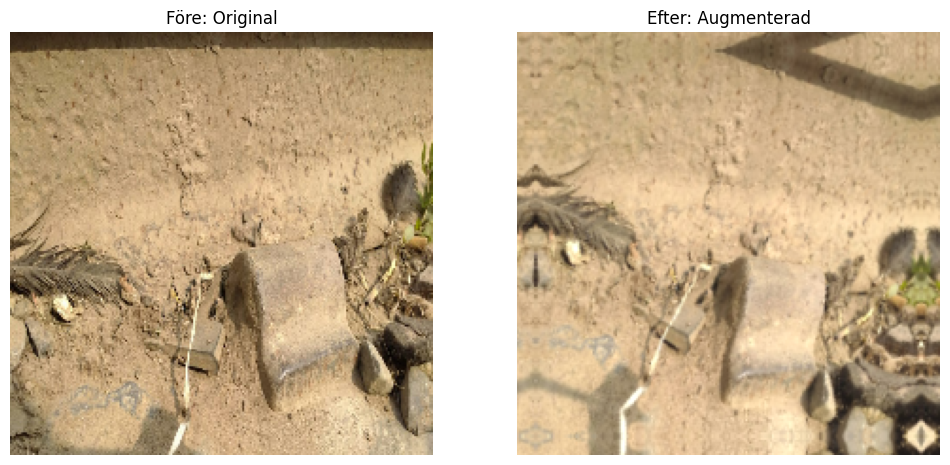

In [ ]:


# Plocka ut EN batch (32 bilder) från träningsdatan
for images, lbls in train_ds.take(1):
    frst_img = images[0]
    
    # För att få plats med två bilder bredvid varandra och jämföra dessa med varandra 
    plt.figure(figsize=(12, 6))
    
    # Plats för orginal bilden till vänster
    plt.subplot(1, 2, 1) 
    
    # Omvandlar 0-255 till 0-1 floats för plt 
    original_to_plot = frst_img.numpy() / 255.0
    original_to_plot = np.clip(original_to_plot, 0, 1)
    
    plt.imshow(original_to_plot)
    plt.title("Före: Original")
    plt.axis("off")
    
    
    # Place for the Augmentated pictures on the right side
    plt.subplot(1, 2, 2) # 1 rad, 2 kolumner, bild 2
    
    # Skickar bilden genom första layer
    augmented_image = data_augmentation(tf.expand_dims(frst_img, 0), training=True)
    
    # Normalisera bilden 
    aug_to_plot = augmented_image[0].numpy()
    aug_to_plot = np.clip(aug_to_plot, 0, 1)
    
    plt.imshow(aug_to_plot)
    plt.title("Efter: Augmenterad")
    plt.axis("off")
    
    # Sparar bilden till rapporten 
    plt.savefig('before_and_after_augmentation.png', bbox_inches='tight')
    plt.show()